In [30]:
# set up libraries
import numpy as np
import matplotlib.pyplot as plt
from astroquery.simbad import Simbad
import astropy.coordinates as coord
import pandas
import scipy
# set up custom query and define which columns we want
customSimbad = Simbad()
customSimbad.add_votable_fields('ra', 'dec', 'mesdistance', 'otype','rvz_radvel', 'rvz_redshift')
#customSimbad.remove_votable_fields('coordinates')
# set RA, Dec and search radius
my_ra = 227.773
my_dec = 5.744
# use 0.25 degrees as an example
my_radius = '0.25d'
# run query
result_table = customSimbad.query_region(coord.SkyCoord(my_ra,my_dec, unit='deg'),radius=my_radius)
# convert output to pandas data frame
df = result_table.to_pandas()

print("The columns in the data frame are:\n",df.columns.values,"\n")
gal_df=df[df['otype']=='G']
print('Selected',len(gal_df),'galaxies')
print(gal_df['rvz_radvel'])

The columns in the data frame are:
 ['main_id' 'ra' 'dec' 'coo_err_maj' 'coo_err_min' 'coo_err_angle'
 'coo_wavelength' 'coo_bibcode' 'rvz_radvel' 'otype' 'rvz_redshift'
 'mesdistance.bibcode' 'mesdistance.dist' 'mesdistance.dist_prec'
 'mesdistance.mespos' 'mesdistance.method' 'mesdistance.minus_err'
 'mesdistance.minus_err_prec' 'mesdistance.plus_err'
 'mesdistance.plus_err_prec' 'mesdistance.qual' 'mesdistance.unit'] 

Selected 1044 galaxies
0       119054.559937
1        11409.332744
3        90714.638059
4        88827.035284
5        71082.792190
            ...      
1175     24246.453647
1178     24496.257268
1179     26011.788402
1180     27184.609507
1181     28230.360399
Name: rvz_radvel, Length: 1044, dtype: float64


In [31]:

options = Simbad.list_votable_fields()
# to print only the available bundles of columns
options[options["type"] == "bundle of basic columns"][["name", "description"]]
print(options[options["type"] == "velocity"])

name description type
---- ----------- ----


In [32]:
Simbad.list_votable_fields()[70:80]


name,description,type
object,object,object
rvz_bibcode,Radial velocity / redshift reference,column of basic
rvz_err,Radial velocity / redshift error,column of basic
rvz_err_prec,Radial velocity / redshift error precision,column of basic
rvz_nature,velocity / redshift nature,column of basic
rvz_qual,Radial velocity / redshift quality,column of basic
rvz_radvel,Radial Velocity,column of basic
rvz_radvel_prec,Radial velocity precision,column of basic
rvz_redshift,redshift,column of basic
rvz_redshift_prec,redshift precision,column of basic


Text(0, 0.5, 'Number of galaxies')

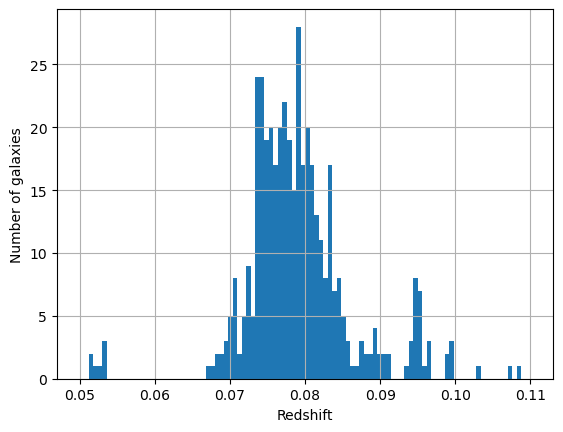

In [33]:
gal_df['rvz_redshift'].hist(bins=100, range=(0.05,0.11))
plt.xlabel('Redshift')
plt.ylabel('Number of galaxies')

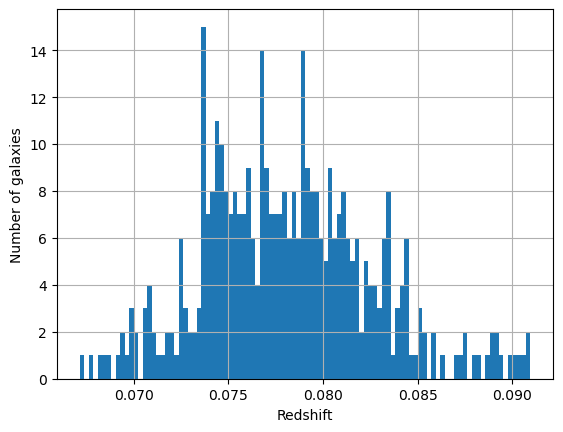

<function matplotlib.pyplot.show(close=None, block=None)>

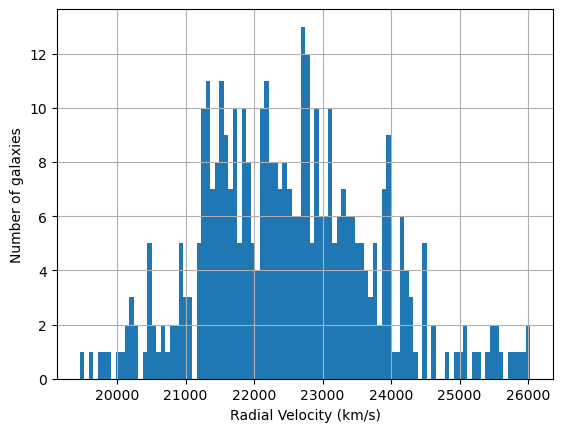

In [34]:
galaxy_cluster = gal_df[(gal_df['rvz_redshift'] <0.093 )& (gal_df['rvz_redshift'] >0.065)]
galaxy_cluster['rvz_redshift'].hist(bins=100)
plt.xlabel('Redshift')
plt.ylabel('Number of galaxies')
plt.show()
galaxy_cluster['rvz_radvel'].hist(bins=100)
plt.xlabel('Radial Velocity (km/s)')
plt.ylabel('Number of galaxies')
plt.show

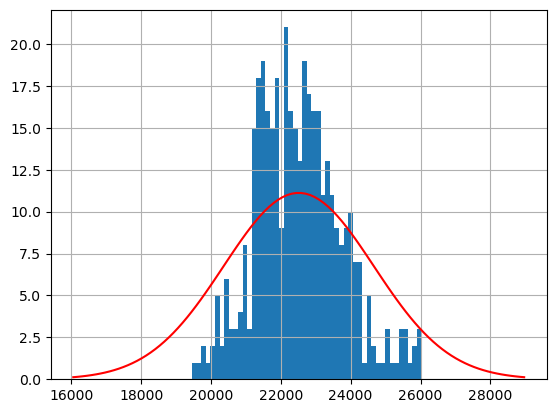

In [35]:
standardised_plot = galaxy_cluster['rvz_radvel']
standardised_plot.hist(bins=50)
import scipy.stats as stats
mean =galaxy_cluster['rvz_radvel'].mean()
standarddev= galaxy_cluster['rvz_radvel'].std()*np.sqrt(3)
x = np.linspace(mean - 3*standarddev, mean + 3*standarddev, 100)
plt.plot(x, stats.norm.pdf(x, mean, standarddev)*(60000),'r')
plt.show()

In [36]:
import astropy.constants as cons
import scipy.constants as math_cons
from astropy.cosmology import WMAP7 as cosmo
from astropy import units as u
import astropy.cosmology.units as cu

redshift = 0.0766
rho_200 = 200*cosmo.critical_density(redshift).to(u.kg/u.m**3)
standarddev_SI = standarddev*(u.km/u.s)
M_200 = np.sqrt(((27)/(cons.G**3))*(standarddev_SI**6)*((3)/(4*math_cons.pi*rho_200)))
M_200 = M_200.to(u.solMass)
print(M_200)
R_200 = (3*M_200/(4*math_cons.pi*rho_200))**(1/3)
R_200 = R_200.to(u.kpc)/cosmo.kpc_proper_per_arcmin(redshift)

print(R_200)


1.6568016571014712e+16 solMass
59.101925029186155 arcmin
